In [1]:
import sys
import numpy as np
sys.path.append("src")
import matplotlib.pyplot as plt
#from helpers import load_csv_data
from src.helpers import *            # load_csv_data, create_csv_submission
from src.implementations import *    # your 6 functions from Table 1

Données chargées : (328135, 321)


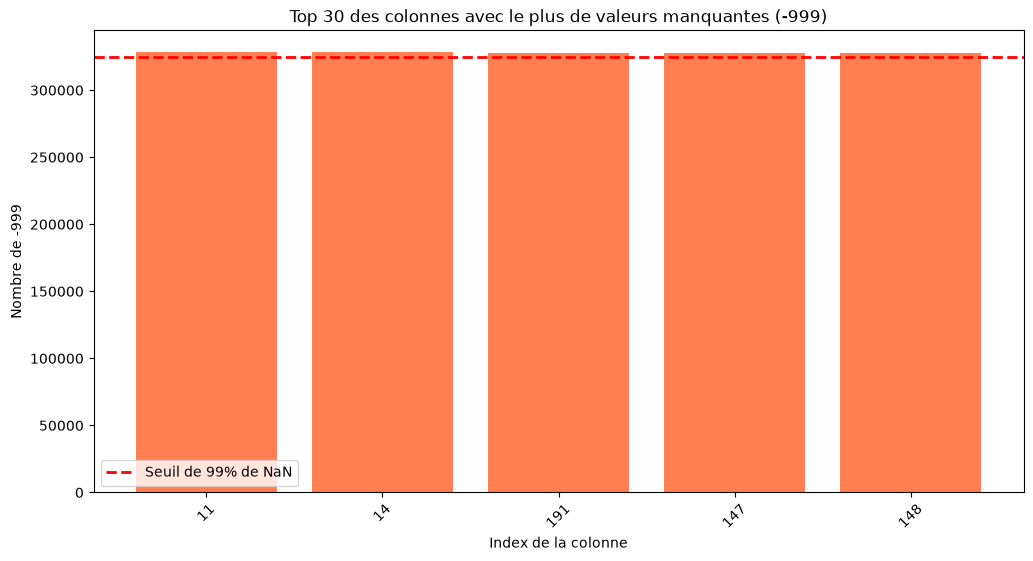

In [2]:


# 1. Charger les données avec la fonction officielle de votre groupe
DATA_PATH = "data/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
print("Données chargées :", x_train.shape)

# 2. PLOT : Compter les -999 par colonne (en pur Numpy !)
missing_counts = np.sum(np.isnan(x_train), axis=0)

# Filtrer pour ne garder que les colonnes qui ont des -999 et les trier
cols_with_missing = np.where(missing_counts > 0)[0]
counts = missing_counts[cols_with_missing]

# Tri décroissant
sort_indices = np.argsort(counts)[::-1]
top_counts = counts[sort_indices][:5] # On prend le top 30
top_cols = cols_with_missing[sort_indices][:5]

# 1. Calculer combien représentent 99% des lignes
seuil_99 = 0.99 * x_train.shape[0]



plt.figure(figsize=(12, 6))
plt.bar([str(c) for c in top_cols], top_counts, color='coral')
plt.title("Top 30 des colonnes avec le plus de valeurs manquantes (-999)")
plt.xlabel("Index de la colonne")
plt.ylabel("Nombre de -999")
plt.xticks(rotation=45)
# ligne horizontale en pointillé rouge qui montre les colonnes 99% de nan
plt.axhline(y=seuil_99, color='red', linestyle='--', linewidth=2, label='Seuil de 99% de NaN')
plt.legend()
plt.show()



Minimal preprcoessing 

In [3]:
#1. Calculer les NaN sur le set d'entraînement
missing_counts = np.sum(np.isnan(x_train), axis=0)
seuil_99 = 0.99 * x_train.shape[0]

# 2. Identifier les colonnes saines (moins de 99% de NaN)
colonnes_a_garder = np.where(missing_counts < seuil_99)[0]

# 3. Mettre à jour x_train et x_test avec uniquement ces colonnes
x_train = x_train[:, colonnes_a_garder]
x_test = x_test[:, colonnes_a_garder]

print(f"Nettoyage : {len(missing_counts) - len(colonnes_a_garder)} colonnes inutiles supprimées.")


# Replace missing values (NaN) by the column median computed on the TRAIN set
median = np.nan_to_num(np.nanmedian(x_train, axis=0))
x_train = np.where(np.isnan(x_train), median, x_train)
x_test = np.where(np.isnan(x_test), median, x_test)

# Standardize with train statistics
mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
std[std == 0] = 1                     # avoid division by zero
x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

# Add the offset (bias) column -> tx, as in the labs
tx_train = np.c_[np.ones(x_train.shape[0]), x_train]
tx_test = np.c_[np.ones(x_test.shape[0]), x_test]

# Labels in {0,1} for logistic regression
y = (y_train + 1) / 2

Nettoyage : 30 colonnes inutiles supprimées.


In [4]:
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 200
gamma = 0.1
lambda_ = 1e-4

w, loss = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
print("train loss:", loss)

NameError: name 'tx_tr' is not defined

In [ ]:
def split_data(y, tx, ratio, seed=1):
    """Randomly split the data into train and validation sets."""
    np.random.seed(seed)
    idx = np.random.permutation(len(y))
    cut = int(ratio * len(y))
    return tx[idx[:cut]], y[idx[:cut]], tx[idx[cut:]], y[idx[cut:]]

tx_tr, y_tr, tx_val, y_val = split_data(y, tx_train, ratio=0.8)

def sigmoid(t):
    return 1.0 / (1.0 + np.exp(-t))

def predict_labels(w, tx, threshold=0.15):
    """Return predictions in {-1, 1} (format required by the submission)."""
    return np.where(sigmoid(tx @ w) >= threshold, 1, -1)

def f1_score(y_true, y_pred):
    """F1 score for labels in {-1, 1}."""
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))
    return 2 * tp / (2 * tp + fp + fn + 1e-12)

y_val_pm = 2 * y_val - 1             # back to {-1, 1}
y_pred_val = predict_labels(w, tx_val)
print("accuracy:", np.mean(y_pred_val == y_val_pm))
print("F1 score:", f1_score(y_val_pm, y_pred_val))

accuracy: 0.7611044234842367
F1 score: 0.35814296241709653


In [ ]:
DATA_PATH = "data/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

# 1. Définir le seuil et compter les NaN
seuil_99 = 0.99 * x_train.shape[0]
missing_counts = np.sum(np.isnan(x_train), axis=0)

# 2. Trouver les colonnes à garder (celles qui ont strictement moins de 99% de NaN)
colonnes_a_garder = np.where(missing_counts < seuil_99)[0]
nb_supprimees = x_train.shape[1] - len(colonnes_a_garder)
print(f"On a supprimé {nb_supprimees} colonnes inutiles !")

# 3. Filtrer les données d'entraînement
x_train_filtre = x_train[:, colonnes_a_garder]

# ==========================================
# REPRODUCTION DU PIPELINE DE TON GROUPE
# ==========================================

# Remplacer les NaN restants par la médiane de chaque colonne filtrée
median = np.nanmedian(x_train_filtre, axis=0)
x_train_imputed = np.where(np.isnan(x_train_filtre), median, x_train_filtre)

# Standardisation
mean_x = np.mean(x_train_imputed, axis=0)
std_x = np.std(x_train_imputed, axis=0)
std_x[std_x == 0] = 1 # Eviter la division par 0
tx_train_std = (x_train_imputed - mean_x) / std_x

# Ajouter la colonne de biais (des 1)
tx_train_final = np.c_[np.ones(tx_train_std.shape[0]), tx_train_std]

# Labels pour la régression logistique (de {-1, 1} vers {0, 1})
y = (y_train + 1) / 2

# Split Train/Validation (Assure-toi que la fonction split_data est bien chargée)
tx_tr, y_tr, tx_val, y_val = split_data(y, tx_train_final, ratio=0.8)

# Paramètres d'entraînement du groupe
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 200
gamma = 0.1
lambda_ = 1e-4

# Entraînement 
w, loss = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
print("Train loss:", loss)

# Évaluation sur le set de validation
y_val_pm = 2 * y_val - 1 # Retour aux labels originaux {-1, 1}
y_pred_val = predict_labels(w, tx_val)

print("Ancien F1 score : 0.1316")
print("NOUVEAU F1 score :", f1_score(y_val_pm, y_pred_val))

On a supprimé 30 colonnes inutiles !
Train loss: 0.2430515051912906
Ancien F1 score : 0.1316
NOUVEAU F1 score : 0.35814296241709653


## TEST RUN WITH MODELS.PY

In [6]:
import sys
import numpy as np
sys.path.append("src")

from src.helpers import load_csv_data
from src.special_function import read_column_names, apply_special_functions
from models import compute_pca, logistic_regression_train, logistic_regression_predict

# recap preprocess de au dessus
def split_data(y, tx, ratio, seed=1):
    np.random.seed(seed)
    idx = np.random.permutation(len(y))
    cut = int(ratio * len(y))
    return tx[idx[:cut]], y[idx[:cut]], tx[idx[cut:]], y[idx[cut:]]

def f1_score(y_true, y_pred):
    """F1 score pour des labels dans {-1, 1}."""
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))
    return 2 * tp / (2 * tp + fp + fn + 1e-12)


# ÉTAPE 1 : CHARGEMENT & SPECIAL FUNCTIONS
DATA_PATH = "data/"
print("1. Chargement des données...")
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
names = read_column_names(DATA_PATH + "x_train.csv")

print("2. Application des special functions de Léon...")
x_train, train_names = apply_special_functions(x_train, names)
print("Nouvelle forme après décodage :", x_train.shape)

# ÉTAPE 2 : PREPROCESSING MINIMAL

# Supprimer les colonnes avec >= 99% de NaN
seuil_99 = 0.99 * x_train.shape[0]
missing_counts = np.sum(np.isnan(x_train), axis=0)
colonnes_a_garder = np.where(missing_counts < seuil_99)[0]
x_train_filtre = x_train[:, colonnes_a_garder]
print(f"Colonnes gardées : {len(colonnes_a_garder)} / {x_train.shape[1]}")

# Convertir {-1, 1} vers {0, 1}
y = (y_train + 1) / 2

# Split Train / Validation AVANT de calculer médiane/moyenne/PCA (évite le data leakage !)
X_tr, y_tr, X_val, y_val = split_data(y, x_train_filtre, ratio=0.8)

# Remplacer les NaN par la médiane 
median = np.nan_to_num(np.nanmedian(X_tr, axis=0))
X_tr = np.where(np.isnan(X_tr), median, X_tr)
X_val = np.where(np.isnan(X_val), median, X_val)

# Standardisation
mean_x = np.mean(X_tr, axis=0)
std_x = np.std(X_tr, axis=0)
std_x[std_x == 0] = 1
X_tr_std = (X_tr - mean_x) / std_x
X_val_std = (X_val - mean_x) / std_x

# ÉTAPE 3 : PCA

nb_composantes = 250
print(f"3. Calcul de la PCA ({nb_composantes} composantes)...")

# On calcule la PCA sur le train set
X_tr_pca, vecteurs_pca = compute_pca(X_tr_std, num_components=nb_composantes)

# On projette le validation set avec les MÊMES vecteurs_pca
X_val_meaned = X_val_std - np.mean(X_tr_std, axis=0)
X_val_pca = np.dot(X_val_meaned, vecteurs_pca)

print("Forme de X_tr_pca :", X_tr_pca.shape)




# ÉTAPE 4 : MODEL

print("4. Entraînement de la régression logistique pondérée...")

# On teste différents poids pour la classe minoritaire
for weight in [4.0, 4.25, 4.5, 4.75]:
    print(f"\n--- Test avec minority_weight = {weight} ---")
    w, b = logistic_regression_train(
        X_tr_pca, y_tr, 
        lr=0.1, 
        epochs=300, 
        minority_weight=weight
    )
    
    # Prédiction renvoie 0 ou 1
    y_pred_01 = logistic_regression_predict(X_val_pca, w, b, threshold=0.5)
    
    # Reconvertir en {-1, 1} pour calculer le F1-score et l'accuracy
    y_pred_pm = 2 * y_pred_01 - 1
    y_val_pm = 2 * y_val - 1
    
    acc = np.mean(y_pred_pm == y_val_pm)
    f1 = f1_score(y_val_pm, y_pred_pm)
    print(f"Résultat -> Accuracy: {acc:.4f} | F1 score: {f1:.4f}")

1. Chargement des données...
2. Application des special functions de Léon...
Nouvelle forme après décodage : (328135, 321)
Colonnes gardées : 291 / 321
3. Calcul de la PCA (250 composantes)...
Forme de X_tr_pca : (262508, 250)
4. Entraînement de la régression logistique pondérée...

--- Test avec minority_weight = 4.0 ---
Résultat -> Accuracy: 0.8633 | F1 score: 0.4060

--- Test avec minority_weight = 4.25 ---
Résultat -> Accuracy: 0.8570 | F1 score: 0.4034

--- Test avec minority_weight = 4.5 ---
Résultat -> Accuracy: 0.8512 | F1 score: 0.4017

--- Test avec minority_weight = 4.75 ---
Résultat -> Accuracy: 0.8449 | F1 score: 0.3979


In [7]:
# ==========================================
# ÉTAPE 3 & 4 : RECHERCHE DES MEILLEURS HYPERPARAMÈTRES
# ==========================================
best_f1 = 0
best_params = {}

for nb_comp in [100, 150, 200, 250]:
    # Calcul de la PCA pour ce nombre de composantes
    X_tr_pca, vecteurs_pca = compute_pca(X_tr_std, num_components=nb_comp)
    X_val_meaned = X_val_std - np.mean(X_tr_std, axis=0)
    X_val_pca = np.dot(X_val_meaned, vecteurs_pca)
    
    for weight in [3.5, 4.0, 4.5, 5.0]:
        w, b = logistic_regression_train(
            X_tr_pca, y_tr,
            lr=0.1,
            epochs=600,
            minority_weight=weight
        )
        
        # On teste plusieurs seuils de probabilité (instantanné !)
        for thresh in [0.45, 0.50, 0.55, 0.60]:
            y_pred_01 = logistic_regression_predict(X_val_pca, w, b, threshold=thresh)
            y_pred_pm = 2 * y_pred_01 - 1
            y_val_pm = 2 * y_val - 1
            
            f1 = f1_score(y_val_pm, y_pred_pm)
            acc = np.mean(y_pred_pm == y_val_pm)
            
            if f1 > best_f1:
                best_f1 = f1
                best_params = {
                    "nb_comp": nb_comp,
                    "weight": weight,
                    "thresh": thresh,
                    "acc": acc
                }
                print(f"Nouveau record ! F1: {f1:.4f} (Acc: {acc:.4f}) -> PCA={nb_comp}, weight={weight}, thresh={thresh}")

print("\n=== MEILLEURE CONFIGURATION TROUVÉE ===")
print(best_params)
print(f"Meilleur F1 score : {best_f1:.4f}")

Nouveau record ! F1: 0.3890 (Acc: 0.8574) -> PCA=100, weight=3.5, thresh=0.45
Nouveau record ! F1: 0.3893 (Acc: 0.8637) -> PCA=100, weight=4.0, thresh=0.5
Nouveau record ! F1: 0.3948 (Acc: 0.8569) -> PCA=150, weight=3.5, thresh=0.45
Nouveau record ! F1: 0.3993 (Acc: 0.8578) -> PCA=200, weight=3.5, thresh=0.45
Nouveau record ! F1: 0.4058 (Acc: 0.8577) -> PCA=250, weight=3.5, thresh=0.45
Nouveau record ! F1: 0.4082 (Acc: 0.8642) -> PCA=250, weight=4.0, thresh=0.5

=== MEILLEURE CONFIGURATION TROUVÉE ===
{'nb_comp': 250, 'weight': 4.0, 'thresh': 0.5, 'acc': np.float64(0.8642479467292425)}
Meilleur F1 score : 0.4082


# Test run with preprocessed data


## Preprocessing

In [2]:

import sys
import numpy as np

sys.path.append("src")

from src.helpers import load_csv_data
from src.preprocess import preprocess, load_metadata
from src.models import (
    compute_pca,
    logistic_regression_train,
    logistic_regression_predict
)

# 1. Charger les données brutes
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data/")

# Labels : {-1, 1} -> {0, 1}
y = (y_train + 1) / 2

# 2. Séparer training / validation AVANT preprocessing
rng = np.random.default_rng(1)
indices = rng.permutation(len(y))
cut = int(0.8 * len(y))

idx_tr = indices[:cut]
idx_val = indices[cut:]

X_tr_raw = x_train[idx_tr]
X_val_raw = x_train[idx_val]

y_tr = y[idx_tr]
y_val = y[idx_val]

# 3. Nouveau preprocessing d'Anna
metadata = load_metadata()

X_tr, X_val = preprocess(
    X_tr_raw,
    X_val_raw,
    metadata
)

print("Train shape:", X_tr.shape)
print("Validation shape:", X_val.shape)

# Vérifier les NaN et valeurs infinies
print("NaN train:", np.isnan(X_tr).sum())
print("NaN validation:", np.isnan(X_val).sum())

if not np.all(np.isfinite(X_tr)) or not np.all(np.isfinite(X_val)):
    raise ValueError("Preprocessing contains NaN or infinite values")





Train shape: (262508, 818)
Validation shape: (65627, 818)
NaN train: 0
NaN validation: 0


## Configuration

In [3]:
USE_PCA = False
USE_UPSAMPLING = True
UPSAMPLE_FACTOR = 3
MINORITY_WEIGHT = 1.0

## PCA

In [4]:

USE_PCA = True  # Change to False to disable PCA
num_components = 250

if USE_PCA:
    # PCA calculated only on training data
    X_tr_model, components = compute_pca(
        X_tr, num_components
    )

    # Apply the SAME PCA to validation data
    train_mean = np.mean(X_tr, axis=0)
    X_val_model = (X_val - train_mean) @ components

    print(f"PCA applied: {X_tr_model.shape[1]} components")

else:
    X_tr_model = X_tr
    X_val_model = X_val

    print("PCA disabled")


PCA applied: 250 components


In [5]:
import numpy as np
from src.implementations import (
    mean_squared_error_gd,
    mean_squared_error_sgd,
    least_squares,
    ridge_regression,
    logistic_regression as standard_logistic_regression,
)

# Use the same processed data for every new model (with or without PCA).
# X_tr_model and X_val_model come from your PCA cell above.
tx_train_models = np.column_stack((np.ones(len(X_tr_model)), X_tr_model))
tx_val_models = np.column_stack((np.ones(len(X_val_model)), X_val_model))
y_train_models = np.asarray(y_tr, dtype=float)
y_val_models = np.asarray(y_val, dtype=int)

# Fixed threshold for this first comparison (NOT tuned yet).
FIXED_THRESHOLD = 0.20
results_models = {}

def evaluate_model(name, validation_scores, train_loss):
    """Convert scores to binary predictions, then compute F1 and accuracy."""
    if not np.all(np.isfinite(validation_scores)):
        raise ValueError(f"{name}: non-finite predictions; check training convergence.")
    pred = (validation_scores >= FIXED_THRESHOLD).astype(int)
    tp = np.sum((y_val_models == 1) & (pred == 1))
    fp = np.sum((y_val_models == 0) & (pred == 1))
    fn = np.sum((y_val_models == 1) & (pred == 0))
    precision = tp / (tp + fp + 1e-12)
    recall = tp / (tp + fn + 1e-12)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)
    accuracy = np.mean(pred == y_val_models)
    results_models[name] = (f1, accuracy, precision, recall)
    print(f"{name}: loss={train_loss:.4f} | F1={f1:.4f} | "
          f"accuracy={accuracy:.4f} | precision={precision:.4f} | recall={recall:.4f}")

print("Train:", tx_train_models.shape, "Validation:", tx_val_models.shape)
print("Positive rate:", round(np.mean(y_train_models), 4))
print("Fixed threshold:", FIXED_THRESHOLD)

Train: (262508, 251) Validation: (65627, 251)
Positive rate: 0.0881
Fixed threshold: 0.2


## 1. Weighted Logistic Regression

In [6]:

import numpy as np
from src.models import logistic_regression_train

# Same data as our previous best result (no PCA)
X_train_model = X_tr
X_validation_model = X_val

# Parameters to test
weights = [4.0, 5.0, 6.0]
thresholds = np.arange(0.30, 0.751, 0.025)

best_f1 = -1
best_params = {}
best_w, best_b = None, None

for weight in weights:

    # Train ONCE for each weight
    w, b = logistic_regression_train(
        X_train_model,
        y_tr,
        lr=0.1,
        epochs=600,
        minority_weight=weight
    )

    # Compute probabilities only once
    z = np.clip(X_validation_model @ w + b, -50, 50)
    probabilities = 1 / (1 + np.exp(-z))

    for threshold in thresholds:

        pred = (probabilities >= threshold).astype(int)

        tp = np.sum((y_val == 1) & (pred == 1))
        fp = np.sum((y_val == 0) & (pred == 1))
        fn = np.sum((y_val == 1) & (pred == 0))

        precision = tp / (tp + fp + 1e-12)
        recall = tp / (tp + fn + 1e-12)
        f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)
        acc = np.mean(pred == y_val)

        if f1 > best_f1:
            best_f1 = f1
            best_params = {
                "weight": weight,
                "threshold": round(float(threshold), 3),
                "accuracy": acc,
                "precision": precision,
                "recall": recall
            }
            best_w = w.copy()
            best_b = b

    print(f"Weight {weight} tested.")

print("\n--- BEST CONFIGURATION ---")
print("Best F1:", round(best_f1, 4))
print("Best parameters:", best_params)


Weight 4.0 tested.
Weight 5.0 tested.
Weight 6.0 tested.

--- BEST CONFIGURATION ---
Best F1: 0.4393
Best parameters: {'weight': 5.0, 'threshold': 0.55, 'accuracy': np.float64(0.8717143858472884), 'precision': np.float64(0.3602796591653921), 'recall': np.float64(0.5627026104760279)}


# Weighted Logistic Regression + L2 regularization

In [10]:


def weighted_logistic_l2(X, y, lr=0.1, epochs=600,
                         minority_weight=5.0, lambda_=0.001):

    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0

    sample_weights = np.where(y == 1, minority_weight, 1.0)

    for epoch in range(epochs):

        z = np.clip(X @ w + b, -50, 50)
        pred = 1 / (1 + np.exp(-z))

        error = (pred - y) * sample_weights

        # Weighted gradient + L2 regularization
        dw = X.T @ error / n_samples + 2 * lambda_ * w
        db = np.mean(error)

        w -= lr * dw
        b -= lr * db

    return w, b


# Test different regularization strengths
for lambda_ in [0.0001, 0.001, 0.01]:

    w, b = weighted_logistic_l2(
        X_tr, y_tr,
        minority_weight=5.0,
        lambda_=lambda_
    )

    z = np.clip(X_val @ w + b, -50, 50)
    probabilities = 1 / (1 + np.exp(-z))

    best_f1 = 0
    best_threshold = None

    for threshold in np.arange(0.4, 0.751, 0.025):

        pred = (probabilities >= threshold).astype(int)

        tp = np.sum((y_val == 1) & (pred == 1))
        fp = np.sum((y_val == 0) & (pred == 1))
        fn = np.sum((y_val == 1) & (pred == 0))

        f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    print(
        f"lambda={lambda_} -> "
        f"Best F1={best_f1:.4f}, "
        f"threshold={best_threshold:.3f}"
    )

KeyboardInterrupt: 

## 2. Regularized Logistic Regression

### Upsampling

In [ ]:

import numpy as np
from src.implementations import reg_logistic_regression

rng = np.random.default_rng(42)

# 1. Upsampling on training data ONLY
positive_idx = np.where(y_tr == 1)[0]

upsample_factor = 4

extra_idx = rng.choice(
    positive_idx,
    size=(upsample_factor - 1) * len(positive_idx),
    replace=True
)

indices_up = np.concatenate([
    np.arange(len(y_tr)),
    extra_idx
])

rng.shuffle(indices_up)

X_up = X_tr[indices_up]
y_up = y_tr[indices_up]

print("Original train size:", len(y_tr))
print("Upsampled train size:", len(y_up))
print("Positive ratio before:", np.mean(y_tr == 1))
print("Positive ratio after:", np.mean(y_up == 1))

# 2. Add bias column
tx_train = np.column_stack([
    np.ones(len(X_up)), X_up
])

tx_val = np.column_stack([
    np.ones(len(X_val)), X_val
])

# 3. Train regularized logistic regression
initial_w = np.zeros(tx_train.shape[1])

lambda_ = 0.001
gamma = 0.1
max_iters = 200

w, loss = reg_logistic_regression(
    y_up,
    tx_train,
    lambda_,
    initial_w,
    max_iters,
    gamma
)

print("Training loss:", loss)

# 4. Predictions on ORIGINAL validation set
z = tx_val @ w
probabilities = 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# 5. Evaluate F1
best_f1 = 0
best_threshold = None

for threshold in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:

    pred = (probabilities >= threshold).astype(int)

    tp = np.sum((y_val == 1) & (pred == 1))
    fp = np.sum((y_val == 0) & (pred == 1))
    fn = np.sum((y_val == 1) & (pred == 0))

    f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)

    print(f"Threshold={threshold} -> F1={f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print(f"\nBest F1: {best_f1:.4f}")
print(f"Best threshold: {best_threshold}")


Original train size: 262508
Upsampled train size: 331850
Positive ratio before: 0.08805064988495588
Positive ratio after: 0.2786078047310532
Training loss: 0.4116205471443599
Threshold=0.1 -> F1=0.2651
Threshold=0.15 -> F1=0.3047
Threshold=0.2 -> F1=0.3353
Threshold=0.25 -> F1=0.3638
Threshold=0.3 -> F1=0.3850
Threshold=0.35 -> F1=0.4063
Threshold=0.4 -> F1=0.4213
Threshold=0.45 -> F1=0.4285
Threshold=0.5 -> F1=0.4303

Best F1: 0.4303
Best threshold: 0.5


# 3. MSE Gradient Descent

In [ ]:
# Linear regression by full-batch gradient descent.
# Each iteration uses ALL training rows: start with a modest number.
w_mse_gd, loss_mse_gd = mean_squared_error_gd(
    y_train_models,
    tx_train_models,
    initial_w=np.zeros(tx_train_models.shape[1]),
    max_iters=100,
    gamma=0.001,
)
evaluate_model("MSE GD", tx_val_models @ w_mse_gd, loss_mse_gd)

MSE GD: loss=0.0401 | F1=0.0003 | accuracy=0.9107 | precision=1.0000 | recall=0.0002


# 4. MSE Stochastic Gradient descent 

In [ ]:
# Stochastic GD: one randomly sampled training row per update.
# 50,000 updates are still fewer than one pass over all 262k train rows.
np.random.seed(42)
w_mse_sgd, loss_mse_sgd = mean_squared_error_sgd(
    y_train_models,
    tx_train_models,
    initial_w=np.zeros(tx_train_models.shape[1]),
    max_iters=50000,
    gamma=0.0005,
)
evaluate_model("MSE SGD", tx_val_models @ w_mse_sgd, loss_mse_sgd)

MSE SGD: loss=1542108.0124 | F1=0.1757 | accuracy=0.5785 | precision=0.1064 | recall=0.5030


# 5. Least squares

In [ ]:
# No iterative training. Normal equations may fail with collinear features.
# PCA is recommended for this first test, particularly with one-hot features.
try:
    w_ls, loss_ls = least_squares(y_train_models, tx_train_models)
    evaluate_model("Least Squares", tx_val_models @ w_ls, loss_ls)
except np.linalg.LinAlgError as exc:
    print("Least Squares could not solve the normal equations:", exc)
    print("Try USE_PCA = True, then rerun the PCA and model cells.")

Least Squares: loss=0.0332 | F1=0.4229 | accuracy=0.8538 | precision=0.3265 | recall=0.5999


# 6. Ridge Regression

In [11]:
#hypertuning
lambda_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
thresholds = np.arange(0.05, 0.501, 0.01)

best_f1 = -1
best_params_ridge = {}
best_w_ridge = None

for lambda_ in lambda_values:

    # Train Ridge Regression
    w, loss = ridge_regression(
        y_train_models,
        tx_train_models,
        lambda_=lambda_
    )

    # Numerical predictions (not probabilities)
    scores = tx_val_models @ w

    best_f1_lambda = -1
    best_threshold_lambda = None

    for threshold in thresholds:

        pred = (scores >= threshold).astype(int)

        tp = np.sum((y_val_models == 1) & (pred == 1))
        fp = np.sum((y_val_models == 0) & (pred == 1))
        fn = np.sum((y_val_models == 1) & (pred == 0))

        f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)
        acc = np.mean(pred == y_val_models)

        if f1 > best_f1_lambda:
            best_f1_lambda = f1
            best_threshold_lambda = threshold

        if f1 > best_f1:
            best_f1 = f1
            best_params_ridge = {
                "lambda": lambda_,
                "threshold": round(float(threshold), 3),
                "accuracy": acc,
                "precision": tp / (tp + fp + 1e-12),
                "recall": tp / (tp + fn + 1e-12)
            }
            best_w_ridge = w.copy()

    print(
        f"lambda={lambda_:.5f} -> "
        f"Best F1={best_f1_lambda:.4f}, "
        f"threshold={best_threshold_lambda:.3f}"
    )

print("\n--- BEST RIDGE CONFIGURATION ---")
print("Best F1:", round(best_f1, 4))
print("Best parameters:", best_params_ridge)

# Save the best coefficients
w_ridge = best_w_ridge


lambda=0.00001 -> Best F1=0.4277, threshold=0.220
lambda=0.00010 -> Best F1=0.4277, threshold=0.220
lambda=0.00100 -> Best F1=0.4281, threshold=0.220
lambda=0.01000 -> Best F1=0.4273, threshold=0.210
lambda=0.10000 -> Best F1=0.4273, threshold=0.200

--- BEST RIDGE CONFIGURATION ---
Best F1: 0.4281
Best parameters: {'lambda': 0.001, 'threshold': 0.22, 'accuracy': np.float64(0.8707544151035397), 'precision': np.float64(0.35388560597613994), 'recall': np.float64(0.5415458112950008)}


# 7. Standard Logistic Regression

In [16]:
# Unlike your custom Logistic Regression in models.py, this one
# does NOT use class weighting. This is the required course function.
w_log, loss_log = standard_logistic_regression(
    y_train_models,
    tx_train_models,
    initial_w=np.zeros(tx_train_models.shape[1]),
    max_iters=200,
    gamma=0.05,
)
logits = tx_val_models @ w_log
probabilities_log = 1 / (1 + np.exp(-np.clip(logits, -500, 500)))
evaluate_model("Standard Logistic", probabilities_log, loss_log)

Standard Logistic: loss=0.2688 | F1=0.3819 | accuracy=0.7750 | precision=0.2530 | recall=0.7784


## Tableau comparison

In [17]:
print(f"{'Model':<21} {'F1':>8} {'Accuracy':>10} {'Precision':>11} {'Recall':>9}")
print("-" * 64)
for name, (f1, acc, prec, rec) in results_models.items():
    print(f"{name:<21} {f1:>8.4f} {acc:>10.4f} {prec:>11.4f} {rec:>9.4f}")

print("\nThese initial results all use threshold", FIXED_THRESHOLD)
print("You can tune thresholds, lambda, gamma, and PCA components later.")

Model                       F1   Accuracy   Precision    Recall
----------------------------------------------------------------
Standard Logistic       0.3819     0.7750      0.2530    0.7784

These initial results all use threshold 0.2
You can tune thresholds, lambda, gamma, and PCA components later.


In [18]:
# ==========================================
# COMPARE CLASSIFICATION THRESHOLDS
# ==========================================

model_scores = {
    "MSE GD": tx_val_models @ w_mse_gd,
    "MSE SGD": tx_val_models @ w_mse_sgd,
    "Least Squares": tx_val_models @ w_ls,
    "Ridge Regression": tx_val_models @ w_ridge,
    "Standard Logistic": probabilities_log
}

for name, scores in model_scores.items():

    best_f1 = 0
    best_threshold = None

    # Linear regression outputs are not probabilities
    if name == "Standard Logistic":
        thresholds = np.linspace(0.05, 0.8, 76)
    else:
        thresholds = np.linspace(-0.1, 0.8, 91)

    for threshold in thresholds:

        pred = (scores >= threshold).astype(int)

        tp = np.sum((y_val_models == 1) & (pred == 1))
        fp = np.sum((y_val_models == 0) & (pred == 1))
        fn = np.sum((y_val_models == 1) & (pred == 0))

        f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    print(
        f"{name}: Best F1 = {best_f1:.4f}, "
        f"Threshold = {best_threshold:.3f}"
    )

NameError: name 'w_mse_gd' is not defined